<a href="https://colab.research.google.com/github/smir-nat/Mat-model/blob/main/lab_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1.1.1. Фігури Лісажу

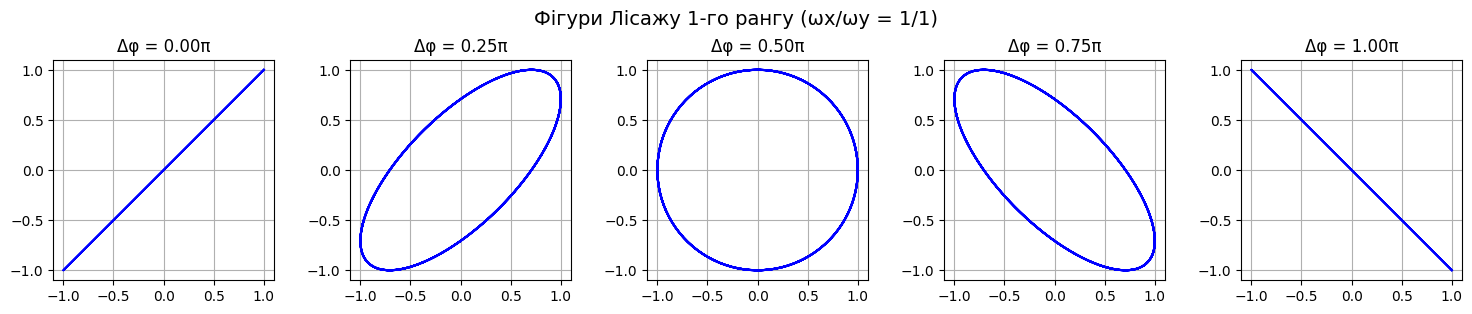

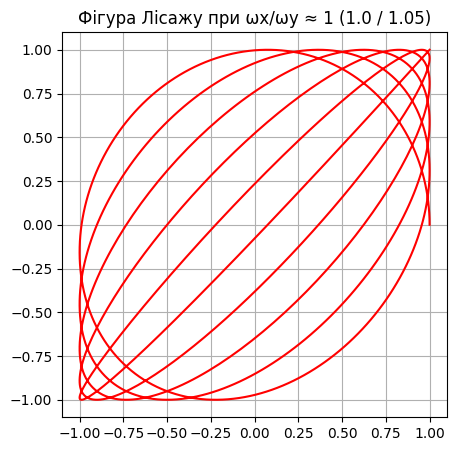

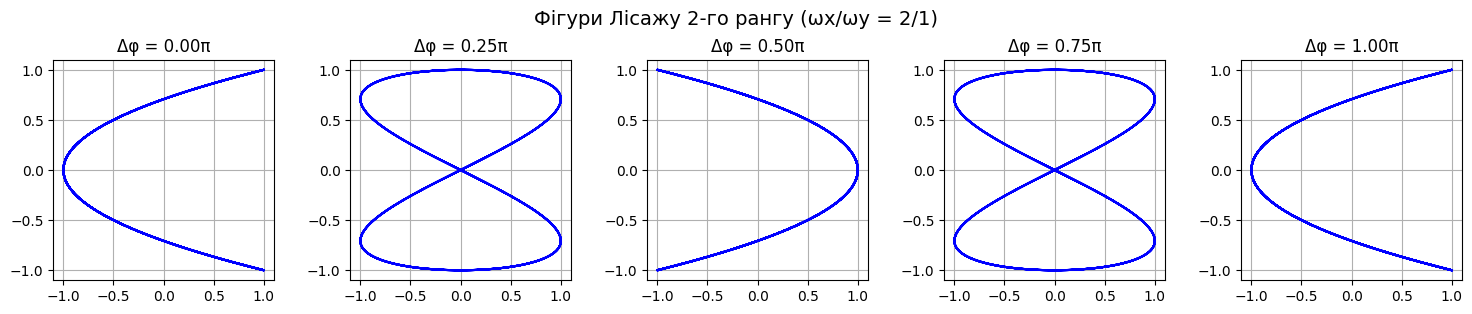

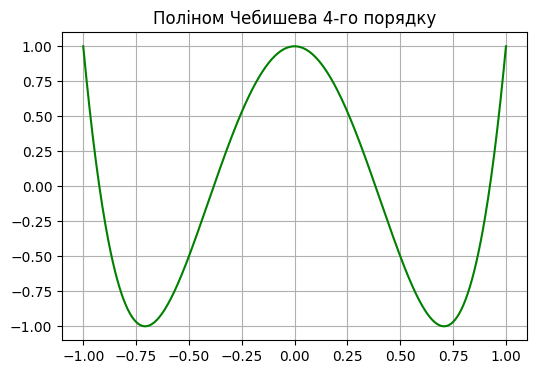

In [1]:
import numpy as np
import matplotlib.pyplot as plt

t = np.linspace(0, 10 * np.pi, 1000)

def plot_lissajous(omega_x, omega_y, title_prefix):
    phases = [0, np.pi/4, np.pi/2, 3*np.pi/4, np.pi]
    fig, axs = plt.subplots(1, 5, figsize=(15, 3))
    fig.suptitle(f'{title_prefix} (ωx/ωy = {omega_x}/{omega_y})', fontsize=14)

    for i, delta_phi in enumerate(phases):
        x = np.cos(omega_x * t)
        y = np.cos(omega_y * t + delta_phi)

        axs[i].plot(x, y, color='blue')
        axs[i].set_title(f'Δφ = {delta_phi/np.pi:.2f}π')
        axs[i].set_xlim([-1.1, 1.1])
        axs[i].set_ylim([-1.1, 1.1])
        axs[i].grid(True)
        axs[i].set_aspect('equal')

    plt.tight_layout()
    plt.show()

plot_lissajous(1, 1, 'Фігури Лісажу 1-го рангу')

fig, ax = plt.subplots(figsize=(5, 5))
x_approx = np.cos(1.0 * t)
y_approx = np.cos(1.05 * t)
ax.plot(x_approx, y_approx, color='red')
ax.set_title('Фігура Лісажу при ωx/ωy ≈ 1 (1.0 / 1.05)')
ax.grid(True)
ax.set_aspect('equal')
plt.show()

plot_lissajous(2, 1, 'Фігури Лісажу 2-го рангу')

n = 4
x_cheb = np.linspace(-1, 1, 400)
T_n = np.cos(n * np.arccos(x_cheb))

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(x_cheb, T_n, color='green')
ax.set_title(f'Поліном Чебишева {n}-го порядку')
ax.grid(True)
plt.show()

1.1.2. Годограф Михайлова

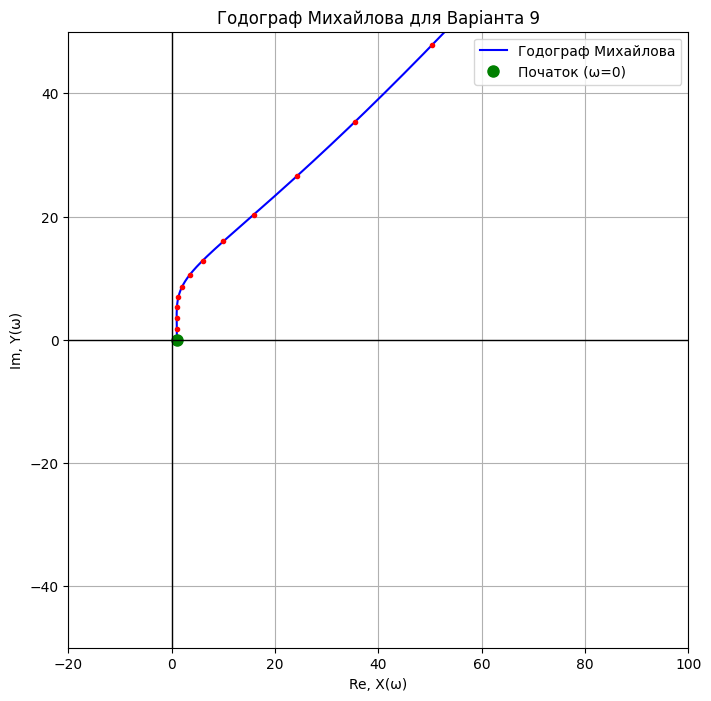

In [3]:
import numpy as np
import matplotlib.pyplot as plt

coeffs = [2, 5, 2, 1, 12, 1]
omega = np.linspace(0, 3, 1000)
p = 1j * omega
D_iw = np.polyval(coeffs, p)

X = np.real(D_iw)
Y = np.imag(D_iw)

plt.figure(figsize=(8, 8))
plt.plot(X, Y, 'b-', label='Годограф Михайлова')

plt.plot(X[::50], Y[::50], 'ro', markersize=3)
plt.plot(X[0], Y[0], 'go', markersize=8, label='Початок (ω=0)')

plt.axhline(0, color='black', linewidth=1)
plt.axvline(0, color='black', linewidth=1)
plt.grid(True)
plt.xlabel('Re, X(ω)')
plt.ylabel('Im, Y(ω)')
plt.title('Годограф Михайлова для Варіанта 9')
plt.legend()

plt.xlim(-20, 100)
plt.ylim(-50, 50)
plt.show()

1.1.3. Банкомат

In [5]:
import random

def atm_model():
    supported_cards = {1: 1234, 2: 5678, 3: 0000}
    hryvnias = random.randint(100, 10000)
    kopecks = random.randint(0, 99)
    balance = hryvnias + kopecks / 100.0
    print("--- a0: Запрошення до вводу картки ---")
    try:
        card_type = int(input("Вставте картку (введіть тип картки, наприклад 1, 2 або 3): "))
    except ValueError:
        card_type = -1

    # a1: Розпізнання картки
    if card_type not in supported_cards:
        print("--- a13: Повідомлення: Тип картки не підтримується! ---")
        return
    print("--- a2: Запрошення до вводу коду ---")
    attempts = 3
    while attempts > 0:
        try:
            pin = int(input(f"Введіть ПІН-код (залишилось спроб - {attempts}): "))
        except ValueError:
            pin = -1
        # a3: Перевірка коду
        if pin == supported_cards[card_type]:
            print("ПІН-код вірний. Доступ дозволено.")
            break
        else:
            attempts -= 1
            if attempts > 0:
                print("--- a11: Запрошення до повторного вводу коду ---")
            else:
                print("--- a12: Повідомлення про невірний код. Картку заблоковано! ---")
                return
    # a4: Вивід меню
    while True:
        print("\n--- a4: Головне меню ---")
        print("1 - Стан рахунку")
        print("2 - Зняття грошей")
        print("3 - Вихід")
        choice = input("Оберіть операцію: ")
        if choice == '1':
            # a5: Вивід стану рахунку
            print(f"--- a5: Стан рахунку: {int(balance)} грн {int(round((balance - int(balance))*100))} коп ---")
        elif choice == '2':
            # a6: Запит на введення суми
            try:
                amount = float(input("--- a6: Введіть суму для зняття: "))
            except ValueError:
                print("Помилка вводу. Спробуйте ще раз.")
                continue
            # a7: Перевірка наявності грошей
            if amount > balance:
                # a9: Повідомлення про недостатню кількість грошей
                print("--- a9: Помилка: Недостатньо грошей на рахунку! ---")
            else:
                # a8: Видача готівки та корегування рахунку
                balance -= amount
                print(f"--- a8: Видача готівки... Видано {amount:.2f} грн. Рахунок відкореговано. ---")
        elif choice == '3':
            # a10: Прощальні вітання
            print("--- a10: Дякуємо за користування банкоматом. До побачення! ---")
            break
        else:
            print("Невідома команда. Будь ласка, оберіть 1, 2 або 3.")

if __name__ == "__main__":
    atm_model()

--- a0: Запрошення до вводу картки ---
Вставте картку (введіть тип картки, наприклад 1, 2 або 3): 1
--- a2: Запрошення до вводу коду ---
Введіть ПІН-код (залишилось спроб - 3): 1111
--- a11: Запрошення до повторного вводу коду ---
Введіть ПІН-код (залишилось спроб - 2): 1234
ПІН-код вірний. Доступ дозволено.

--- a4: Головне меню ---
1 - Стан рахунку
2 - Зняття грошей
3 - Вихід
Оберіть операцію: 1
--- a5: Стан рахунку: 1246 грн 93 коп ---

--- a4: Головне меню ---
1 - Стан рахунку
2 - Зняття грошей
3 - Вихід
Оберіть операцію: 2
--- a6: Введіть суму для зняття: 500
--- a8: Видача готівки... Видано 500.00 грн. Рахунок відкореговано. ---

--- a4: Головне меню ---
1 - Стан рахунку
2 - Зняття грошей
3 - Вихід
Оберіть операцію: 1
--- a5: Стан рахунку: 746 грн 93 коп ---

--- a4: Головне меню ---
1 - Стан рахунку
2 - Зняття грошей
3 - Вихід
Оберіть операцію: 2
--- a6: Введіть суму для зняття: 1000
--- a9: Помилка: Недостатньо грошей на рахунку! ---

--- a4: Головне меню ---
1 - Стан рахунку
2